# Markov chain Monte Carlo (MCMC)

*Beyond the scriptum — an application.*

---

The course has offered three ways to make a random variable with a given density:

| method | what it needs | exercise |
|---|---|---|
| the inverse transform | being able to compute $F^{-1}$ | 4 |
| the rejection method | an envelope $M g \ge f$ that we can sample from | 6 |
| superposition | a decomposition into simpler components | 5 |

Each of them stands on something. What if we **have none of it**? $F^{-1}$ has no closed form, no
sensible envelope can be found, and in higher dimensions the rejection method collapses anyway — in
exercise 8 we saw that in a ball of dimension 20 one point in forty million gets through.

The **Metropolis algorithm** turns the problem around. It does not produce independent samples but
builds a **random walk** that in the long run spends its time exactly where the target density is
large. We pay for it by the samples being **dependent** — and that is precisely why in the notebook
`extra/ch01_05_when_mc_pays_off` we worked out how to compute the error for dependent samples.

In this notebook you see:

- the Metropolis algorithm and why it works (detailed balance)
- **the choice of step**: both too small and too large is bad, and the difference is roughly ninetyfold
- **the burn-in** and error bars for dependent samples
- where MCMC wins: a uniform point in a ball of dimension 20, where rejection has no chance

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


# --- the target density: a mixture of two normals (an unnormalized one would do as well) ---
WEIGHTS = (0.35, 0.65)
CENTRES = (-2.0, 2.5)
DEVIATIONS = (0.8, 1.2)


def target(x):
    '''The density of the mixture. For Metropolis even an unnormalized one suffices — the constant cancels.'''
    return sum(w * math.exp(-((x - m) / s) ** 2 / 2) / (s * math.sqrt(2 * math.pi))
               for w, m, s in zip(WEIGHTS, CENTRES, DEVIATIONS))


EX = sum(w * m for w, m in zip(WEIGHTS, CENTRES))
EX2 = sum(w * (m * m + s * s) for w, m, s in zip(WEIGHTS, CENTRES, DEVIATIONS))
DX = EX2 - EX**2
print(f"the target distribution has exactly: E X = {EX:.5f},  D X = {DX:.5f}")

the target distribution has exactly: E X = 0.92500,  D X = 5.76688


## 1. The Metropolis algorithm

The idea: we build a random walk $X_0, X_1, X_2, \dots$ so that in the long run it dwells in
proportion to the target density $f$.

One step from the state $x$:

1. **Propose** $y = x + \varepsilon$, where $\varepsilon \sim N(0, \sigma)$ (a symmetric proposal).
2. Compute the **ratio** $\displaystyle \alpha = \frac{f(y)}{f(x)}$.
3. If $\alpha \ge 1$, **accept** $y$. Otherwise accept $y$ with probability $\alpha$, and when you do
   not accept, **stay at $x$** (and record $x$ again).

Two things deserve emphasis:

- We need only the **ratio** $f(y)/f(x)$, so the normalizing constant cancels. That is the main reason
  for the popularity of MCMC: in Bayesian statistics the normalizing constant usually cannot be
  computed.
- A rejection **does not mean redrawing**, as in the rejection method. It means recording the same
  value a second time. That is why the samples are dependent.

Point 3 is exactly the Metropolis criterion from simulated annealing
(`extra/ch09_stochastic_algorithms`), except that there it served to find a minimum and here it
serves to generate.

### Why it works

We want $f$ to be the **stationary distribution** of the chain. **Detailed balance** is enough for
that: for all $x, y$

$$f(x)\,P(x \to y) = f(y)\,P(y \to x).$$

Let us check it. For a symmetric proposal the proposal density satisfies $q(x \to y) = q(y \to x)$, so
for $f(y) < f(x)$

$$f(x)\,P(x\to y) = f(x)\,q\,\frac{f(y)}{f(x)} = f(y)\,q = f(y)\,P(y \to x),$$

because the opposite step is always accepted ($\alpha \ge 1$). The equality holds, and so the
stationary distribution is $f$.

In [2]:
def metropolis(density, n, step, x0=0.0):
    '''The Metropolis algorithm with a symmetric normal proposal.

    Returns (samples, the fraction accepted). The samples are DEPENDENT — see section 3.
    '''
    x = x0
    fx = density(x)
    out = []
    accepted = 0
    for _ in range(n):
        y = x + random.gauss(0.0, step)
        fy = density(y)
        if fy >= fx or random.random() < fy / fx:
            x, fx = y, fy
            accepted += 1
        out.append(x)
    return out, accepted / n


N = 200_000
samples, acceptance = metropolis(target, N, step=3.0)
samples = samples[N // 10:]                    # we drop the burn-in, see section 3

m = sum(samples) / len(samples)
v = sum((x - m) ** 2 for x in samples) / (len(samples) - 1)
print(f"accepted {acceptance:.1%} of the proposals")
print(f"E X: {m:.5f}   (exact {EX:.5f})")
print(f"D X: {v:.5f}   (exact {DX:.5f})")
assert abs(m - EX) < 0.05 and abs(v - DX) < 0.2

accepted 52.6% of the proposals
E X: 0.92242   (exact 0.92500)
D X: 5.76562   (exact 5.76688)


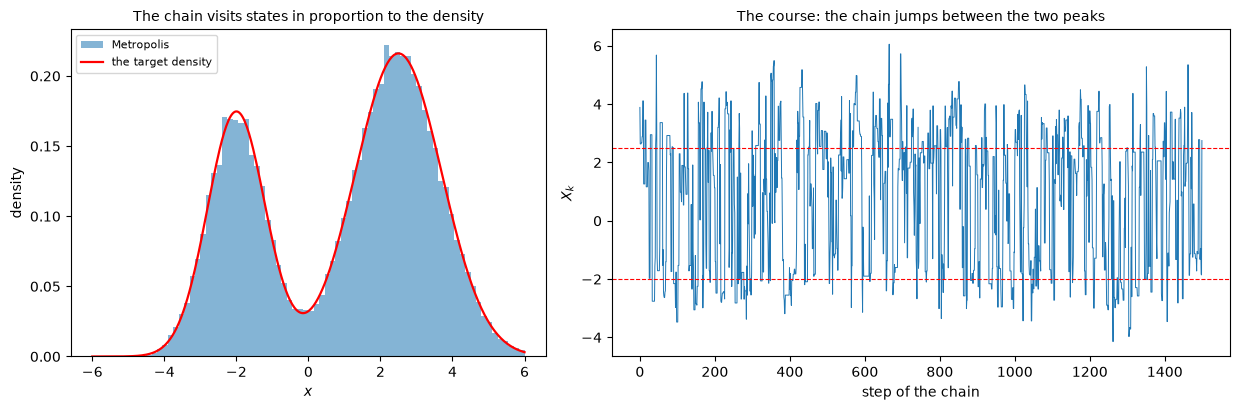

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})

ax = axes[0]
w = 12 / 80
ax.hist(samples, bins=80, range=(-6, 6), weights=[1 / (len(samples) * w)] * len(samples),
        alpha=0.55, label="Metropolis")
gr = [-6 + 12 * i / 400 for i in range(401)]
ax.plot(gr, [target(x) for x in gr], "r", lw=1.6, label="the target density")
ax.set_xlabel("$x$")
ax.set_ylabel("density")
ax.set_title("The chain visits states in proportion to the density", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(range(1500), samples[:1500], lw=0.7)
for m_, s_ in zip(CENTRES, DEVIATIONS):
    ax.axhline(m_, color="r", ls="--", lw=0.8)
ax.set_xlabel("step of the chain")
ax.set_ylabel("$X_k$")
ax.set_title("The course: the chain jumps between the two peaks", fontsize=10)

plt.tight_layout()
plt.show()

The histogram sits on the target density, even though we never computed $F^{-1}$ or looked for an
envelope.

The right-hand plot shows what the chain does: for a while it holds near one peak, then jumps to the
other. Those jumps have to happen often enough, otherwise the ratio of the two peaks would come out
wrong — and how often they happen depends on the **step size**.

## 2. The choice of step: neither small nor large

The step $\sigma$ is the only parameter, and there is trouble on both sides:

- **too small** → almost everything is accepted, but the chain hardly moves and it takes forever to
  traverse the whole distribution,
- **too large** → the proposals land far away in regions of low density, almost everything is
  rejected and the chain stands still.

Both look similar in the trace (the chain does not move) and both can be recognized by the
**autocorrelation time** $\tau$ from the notebook `extra/ch01_05_when_mc_pays_off`: out of $n$
dependent samples we have information equivalent to only about $n/\tau$ independent ones.

In [4]:
def autocorrelation_time(xs, maxlag=400):
    '''τ = 1 + 2 Σ ρ_l, summed until the autocorrelation drops below the noise.'''
    n = len(xs)
    m = sum(xs) / n
    var = sum((v - m) ** 2 for v in xs) / n
    tau = 1.0
    for l in range(1, maxlag):
        c = sum((xs[i] - m) * (xs[i + l] - m) for i in range(n - l)) / ((n - l) * var)
        if c < 0.02:
            break
        tau += 2 * c
    return tau


print(f"{'step σ':>8s} {'accepted':>9s} {'E X':>9s} {'D X':>9s} {'τ':>8s} {'effective samples':>19s}")
steps = (0.2, 1.0, 3.0, 8.0, 25.0)
tau_list, ess_list, ar_list = [], [], []
for step in steps:
    xs, ar = metropolis(target, N, step)
    xs = xs[N // 10:]
    m = sum(xs) / len(xs)
    v = sum((q - m) ** 2 for q in xs) / (len(xs) - 1)
    t = autocorrelation_time(xs[:40_000])
    tau_list.append(t); ess_list.append(len(xs) / t); ar_list.append(ar)
    print(f"{step:>8.1f} {ar:>9.1%} {m:>9.4f} {v:>9.4f} {t:>8.1f} {len(xs) / t:>19,.0f}".replace(",", " "))

print(f"\nBetween the best and the worst step there is a {max(ess_list) / min(ess_list):.0f}-fold difference in the number")
print(f"of effective samples. The optimum lies at an acceptance of around 40 %.")
print(f"\nNotice the first row: at σ = 0.2 the E X comes out {abs(EX - 0.74) / EX:.0%} off. That is not a bias")
print(f"of the algorithm — it is asymptotically unbiased for every step — but τ ≈ {tau_list[0]:.0f} means that")
print("out of " + format(len(xs), ",").replace(",", " ") + f" samples we have the information of only about {ess_list[0]:.0f} independent ones. For that, the gap between")
print(f"the two peaks is simply too large. Little information looks exactly like a wrong result.")

  step σ  accepted       E X       D X        τ   effective samples


     0.2     94.3%    0.7357    5.8611    600.0                 300


     1.0     74.5%    0.9328    5.7889     64.9               2 772


     3.0     52.6%    0.9332    5.7505      7.1              25 216


     8.0     28.4%    0.9143    5.7921      6.7              27 053


    25.0      9.9%    0.9345    5.8104     18.6               9 667

Between the best and the worst step there is a 90-fold difference in the number
of effective samples. The optimum lies at an acceptance of around 40 %.

Notice the first row: at σ = 0.2 the E X comes out 20% off. That is not a bias
of the algorithm — it is asymptotically unbiased for every step — but τ ≈ 600 means that
out of 180 000 samples we have the information of only about 300 independent ones. For that, the gap between
the two peaks is simply too large. Little information looks exactly like a wrong result.


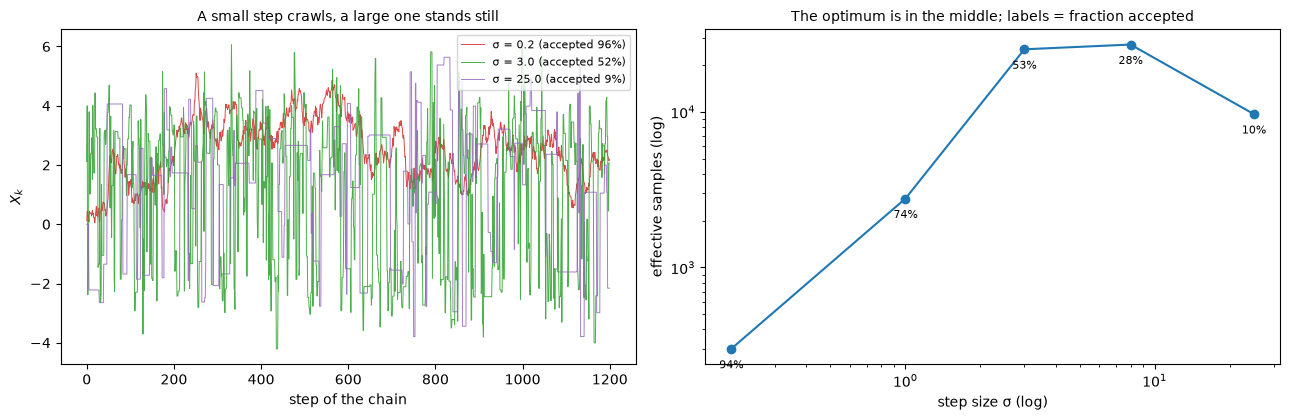

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

ax = axes[0]
for step, color in ((0.2, "tab:red"), (3.0, "tab:green"), (25.0, "tab:purple")):
    xs, ar = metropolis(target, 3000, step)
    ax.plot(xs[:1200], lw=0.7, alpha=0.85, color=color, label=f"σ = {step} (accepted {ar:.0%})")
ax.set_xlabel("step of the chain")
ax.set_ylabel("$X_k$")
ax.set_title("A small step crawls, a large one stands still", fontsize=10)
ax.legend(fontsize=8, loc="upper right")

ax = axes[1]
ax.loglog(steps, ess_list, "o-")
for k_, e_, a_ in zip(steps, ess_list, ar_list):
    ax.annotate(f"{a_:.0%}", (k_, e_), textcoords="offset points", xytext=(0, -14),
                ha="center", fontsize=8)
ax.set_xlabel("step size σ (log)")
ax.set_ylabel("effective samples (log)")
ax.set_title("The optimum is in the middle; labels = fraction accepted", fontsize=10)

plt.tight_layout()
plt.show()

## 3. Burn-in and error bars

Two practical things without which MCMC cannot be used.

### Burn-in

We have to start the chain somewhere, and that start usually has nothing to do with the target
distribution. It takes a while to get there, and the first few thousand steps have to be **thrown
away** — otherwise states where the target density is practically zero would enter our average.

It is exactly the **transient** we saw with the queue in the notebook `extra/ch07_queueing`: the
simulation starts from an atypical state and the beginning of the run is discarded.

### The error bar

The usual formula $\hat\sigma/\sqrt{n}$ holds **only for independent samples**. MCMC samples are not
independent, so it would give an interval that is too narrow and a false confidence. The right answer
is the **block average** from the notebook `extra/ch01_05_when_mc_pays_off`.

                    method  error of the E X estimate
                naive σ/√n                    0.01273
      by blocks (B = 2000)                    0.04133
        actual (60 chains)                    0.03169

The naive formula understates by a factor of 2.5. By blocks it fits.


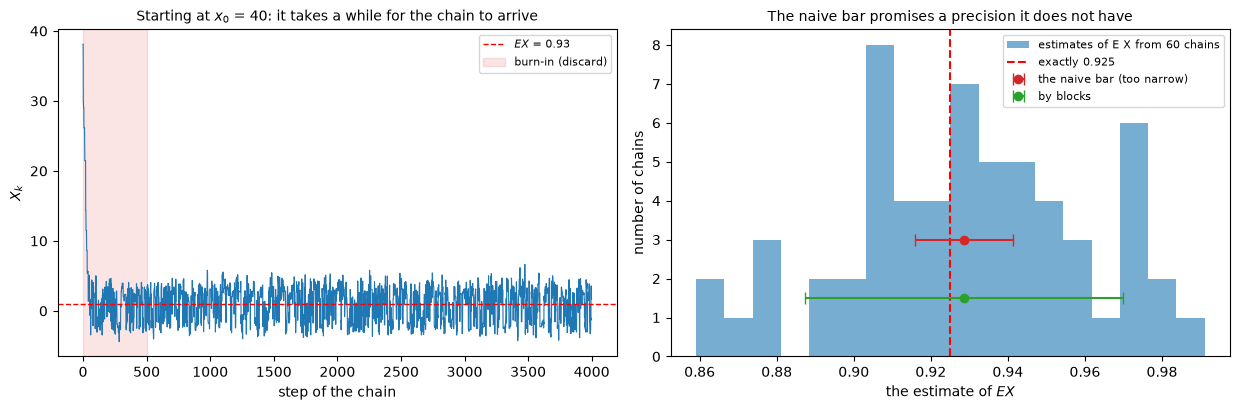

In [6]:
# --- burn-in: starting far from the target ---
far_start = 40.0
chain, _ = metropolis(target, 4000, step=3.0, x0=far_start)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax = axes[0]
ax.plot(chain, lw=0.8)
ax.axhline(EX, color="r", ls="--", lw=1, label=f"$E X$ = {EX:.2f}")
ax.axvspan(0, 500, color="tab:red", alpha=0.12, label="burn-in (discard)")
ax.set_xlabel("step of the chain")
ax.set_ylabel("$X_k$")
ax.set_title(f"Starting at $x_0$ = {far_start:.0f}: it takes a while for the chain to arrive", fontsize=10)
ax.legend(fontsize=8)

# --- error bars: naive vs by blocks ---
def naive_error(xs):
    n = len(xs)
    m = sum(xs) / n
    return math.sqrt(sum((v - m) ** 2 for v in xs) / (n - 1) / n)


def block_error(xs, B=2000):
    nb = len(xs) // B
    blocks = [sum(xs[i * B:(i + 1) * B]) / B for i in range(nb)]
    m = sum(blocks) / nb
    return math.sqrt(sum((v - m) ** 2 for v in blocks) / (nb - 1) / nb)


# the real fluctuation of the estimate: 60 independent chains
estimates = []
for _ in range(60):
    xs_, _ = metropolis(target, 40_000, step=3.0, x0=random.gauss(0, 3))
    estimates.append(sum(xs_[4000:]) / len(xs_[4000:]))
m_e = sum(estimates) / len(estimates)
actual = math.sqrt(sum((v - m_e) ** 2 for v in estimates) / (len(estimates) - 1))

xs_one, _ = metropolis(target, 40_000, step=3.0)
xs_one = xs_one[4000:]
print(f"{'method':>26s} {'error of the E X estimate':>26s}")
print(f"{'naive σ/√n':>26s} {naive_error(xs_one):>26.5f}")
print(f"{'by blocks (B = 2000)':>26s} {block_error(xs_one):>26.5f}")
print(f"{'actual (60 chains)':>26s} {actual:>26.5f}")
print(f"\nThe naive formula understates by a factor of {actual / naive_error(xs_one):.1f}. By blocks it fits.")

ax = axes[1]
ax.hist(estimates, bins=18, alpha=0.6, label="estimates of E X from 60 chains")
ax.axvline(EX, color="r", ls="--", label=f"exactly {EX:.3f}")
ax.errorbar([m_e], [3], xerr=[naive_error(xs_one)], fmt="o", color="tab:red",
            capsize=4, label="the naive bar (too narrow)")
ax.errorbar([m_e], [1.5], xerr=[block_error(xs_one)], fmt="o", color="tab:green",
            capsize=4, label="by blocks")
ax.set_xlabel("the estimate of $E X$")
ax.set_ylabel("number of chains")
ax.set_title("The naive bar promises a precision it does not have", fontsize=10)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The spread of the estimates from sixty independent chains is the truth the two bars are compared with.
The naive formula gives a bar several times narrower than the real fluctuation — it would promise a
precision the estimate does not have. The block average fits.

## 4. Where MCMC really wins: higher dimensions

Until now it was just another route to the same destination — a mixture of two normals can also be
generated by superposition (exercise 5), exactly and independently. The real reason MCMC exists shows
only in higher dimensions.

Take the problem from exercise 8: **a uniform point in the unit ball of dimension $d$**. The rejection
method from a cube has an acceptance probability $V_d / 2^d$, which falls catastrophically with the
dimension — in dimension 20 forty million tries are needed per point.

For Metropolis the problem is easy: the target density is constant inside the ball and zero outside,
so **a proposal is accepted exactly when it lands inside the ball**. We choose the step $\sigma$ so
that this happens often enough.

The check: for a uniform point in a ball

$$E\,\|X\|^2 = \frac{d}{d+2},$$

which we derived in exercise 8.

In [7]:
def ball_metropolis(d, n, step, x0=None):
    '''A uniform point in the unit ball of dimension d. Returns (||x||² at every step, acceptance).'''
    x = [0.0] * d if x0 is None else list(x0)
    r2 = sum(q * q for q in x)
    out, accepted = [], 0
    for _ in range(n):
        y = [xi + random.gauss(0.0, step) for xi in x]
        ry2 = sum(q * q for q in y)
        if ry2 < 1.0:                      # the density is constant inside, zero outside
            x, r2 = y, ry2
            accepted += 1
        out.append(r2)
    return out, accepted / n


def ball_volume(d):
    return math.pi ** (d / 2) / math.gamma(d / 2 + 1)


N2 = 200_000
print(f"{'d':>3s} {'step':>6s} {'acceptance':>11s} {'E||X||² MCMC':>14s} {'exactly d/(d+2)':>16s} "
      f"{'rejection: tries per point':>27s}")
dims, tries = [], []
for d, step in ((2, 0.50), (5, 0.35), (10, 0.22), (20, 0.14)):
    out, ar = ball_metropolis(d, N2, step)
    out = out[N2 // 5:]
    m = sum(out) / len(out)
    exact = d / (d + 2)
    rejection = 2**d / ball_volume(d)
    dims.append(d); tries.append(rejection)
    text = format(rejection, ",.0f").replace(",", " ")
    print(f"{d:>3d} {step:>6.2f} {ar:>11.1%} {m:>14.5f} {exact:>16.5f} {text:>27s}")
    assert abs(m - exact) < 0.01, d

  d   step  acceptance   E||X||² MCMC  exactly d/(d+2)  rejection: tries per point
  2   0.50       61.6%        0.49974          0.50000                           1


  5   0.35       38.2%        0.71397          0.71429                           6


 10   0.22       27.2%        0.83363          0.83333                         402


 20   0.14       16.2%        0.90790          0.90909                  40 631 628


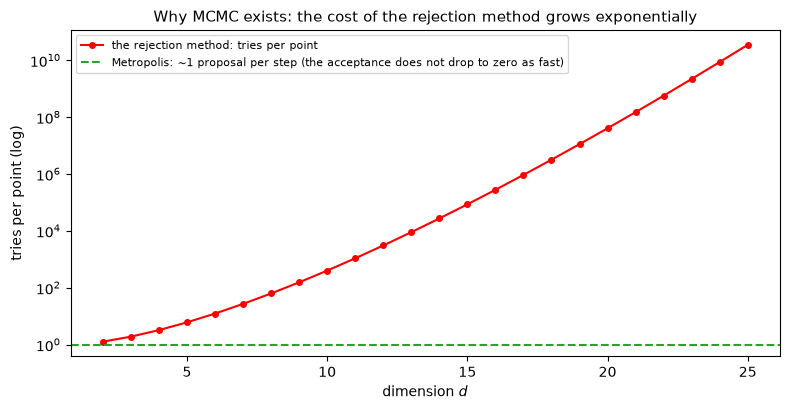

Metropolis, however, does not give INDEPENDENT points — we pay for the easy generation
with autocorrelation, so here too we have to compute τ and the error by blocks.


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.2))
dd = list(range(2, 26))
ax.semilogy(dd, [2**d / ball_volume(d) for d in dd], "r-o", ms=4,
            label="the rejection method: tries per point")
ax.axhline(1.0, color="tab:green", ls="--",
           label="Metropolis: ~1 proposal per step (the acceptance does not drop to zero as fast)")
ax.set_xlabel("dimension $d$")
ax.set_ylabel("tries per point (log)")
ax.set_title("Why MCMC exists: the cost of the rejection method grows exponentially", fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Metropolis, however, does not give INDEPENDENT points — we pay for the easy generation")
print("with autocorrelation, so here too we have to compute τ and the error by blocks.")

The red curve is the cost of the rejection method, the green one roughly the cost of Metropolis. In
low dimensions the rejection method is better — it is simple and gives **independent** samples. From
about dimension ten it turns around, and around twenty the rejection method no longer makes sense.

But be fair in the comparison: Metropolis points are **not independent**. A single step is cheap, but
getting one *effective* sample takes roughly $\tau$ steps. So the green line is optimistic — even so,
it stays many orders of magnitude below the red one.

## Summary

| Concept | What to remember |
|---------|------------------|
| Metropolis | propose $y$, accept with probability $\min(1, f(y)/f(x))$, otherwise stay |
| The normalizing constant | not needed — it cancels in the ratio. The main reason for the popularity |
| Detailed balance | $f(x)P(x\to y) = f(y)P(y\to x)$ ⟹ $f$ is the stationary distribution |
| The choice of step | small = crawls, large = stands still; the optimum at an acceptance of around 40 % |
| The autocorrelation time $\tau$ | out of $n$ samples there is information about only $n/\tau$ independent ones |
| Burn-in | discard the start of the chain — just like the transient of a queue |
| The error bar | the naive $\hat\sigma/\sqrt n$ **understates**; use the block average |
| When to reach for MCMC | when both inversion and the envelope fail, or in higher dimensions |

The main idea: MCMC trades **independence for usability**. The samples are worse (dependent, with a
burn-in, with a step to tune), but we get them even where the other methods have no chance. And since
they are dependent, all the care about error bars from the notebook on dependent realizations carries
over.

### Try it yourself

1. Replace the symmetric proposal with an asymmetric one (an $\operatorname{Exp}$ around $x$, say).
   Then the full Metropolis–Hastings ratio $\frac{f(y)q(y\to x)}{f(x)q(x\to y)}$ is needed. Verify
   that without the correction the distribution comes out wrong.
2. Increase the distance between the two peaks of the mixture (to $\pm 10$, say). How much must $N$
   grow for the estimate of $E X$ to still fit? What does that say about multimodal distributions?
3. Write a **Gibbs** sampler for a two-dimensional normal distribution with correlation $\rho$
   (alternately draw $x \mid y$ and $y \mid x$) and measure $\tau$ as a function of $\rho$.
4. Verify detailed balance numerically: on a fine grid compute $f(x)P(x\to y)$ and $f(y)P(y\to x)$ and
   compare.
5. For a ball in dimension 20 measure $\tau$ and compute the real number of steps per effective
   sample. Is Metropolis still better than the rejection method?
6. Try the Cauchy distribution as the target (exercise 4). Does Metropolis work for heavy tails too?
   What does it do to $\tau$?